# REGLA DE CUADRATURA ADAPTABLE 

# $$\int_a^b f(x)\,dx$$ 


## Codigo 3 
### Materia: Metodos Numéricos II
### Profesor: Ricardo Medel Esquivel 
### Alumno: Salazar Gonzalez Abel 

## Algoritmo 4.3
En el código que se presenta a continuación hemos elaborado el método de Cuadratura Adaptable, en el cual buscaremos integrar funciones mediante la división dinámica del intervalo de integración, ajustando el tamaño y la cantidad de subintervalos según las variaciones de la curva para garantizar que el resultado cumpla con una tolerancia de error específica.

Para comprobar el buen funcionamiento del codigo se usara como ejemplo la ilustracion de la pagina 167 del burden 

$$\int_{1}^{3} \frac{100}{x^2} \sin\left(\frac{10}{x}\right) \, dx=-1.426014$$
#### $$tol= 10^{-4}$$


Ingrese la función f(x) a integrar:  (100 / x**2) * sin(10 / x)
Valor del límite inferior a:  1
Valor del límite superior b:  3
Valor de la tolerancia TOL:  1e-4
Cota N de niveles máximos:  7


El valor de a es: 1.0
El valor de b es: 3.0
El valor de TOL es: 0.0001
El valor de N es: 7

[Paso 1] Aproximación inicial del área Simpson (S_1): -50.80398678832614
Subintervalo aceptado en Nivel 7. APP acumulado = -1.2411235322553495
Subintervalo aceptado en Nivel 7. APP acumulado = -1.60843629661114
Subintervalo aceptado en Nivel 7. APP acumulado = -1.2145108339742867
Subintervalo aceptado en Nivel 7. APP acumulado = -0.20743214913958674
Subintervalo aceptado en Nivel 7. APP acumulado = 1.254414291127802
Subintervalo aceptado en Nivel 7. APP acumulado = 3.0190801236495672
Subintervalo aceptado en Nivel 6. APP acumulado = 6.935717904792657
Subintervalo aceptado en Nivel 6. APP acumulado = 10.718504627900536
Subintervalo aceptado en Nivel 6. APP acumulado = 13.881441804781794
Subintervalo aceptado en Nivel 6. APP acumulado = 16.208167125667607
Subintervalo aceptado en Nivel 6. APP acumulado = 17.66438868310031
Subintervalo aceptado en Nivel 6. APP acumulado = 18.322560088182453
Subinte

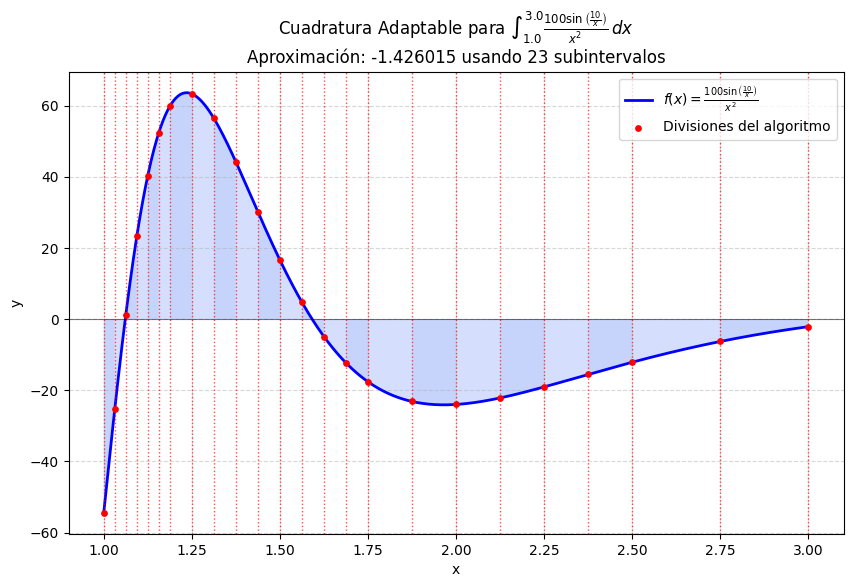

In [1]:
import math
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

x = sp.Symbol('x')
expresion_str = input("Ingrese la función f(x) a integrar: ")
expr = sp.sympify(expresion_str)
f = sp.lambdify(x, expr, modules=['math'])


a = float(sp.sympify(input("Valor del límite inferior a: ")))
b = float(sp.sympify(input("Valor del límite superior b: ")))
TOL = float(sp.sympify(input("Valor de la tolerancia TOL: ")))
N = int(input("Cota N de niveles máximos: "))

print("El valor de a es:", a)
print("El valor de b es:", b)
print("El valor de TOL es:", TOL)
print("El valor de N es:", N)

# Paso 1: Inicializamos las variables
APP = 0.0
i = 1

# Vectores para almacenar las variables de cada nivel 
TOL_i = [0.0, 10.0 * TOL]
a_i = [0.0, a]
h_i = [0.0, (b - a) / 2.0]
FA_i = [0.0, f(a)]
FC_i = [0.0, f(a + h_i[1])]
FB_i = [0.0, f(b)]
S_i = [0.0, h_i[1] * (FA_i[1] + 4.0 * FC_i[1] + FB_i[1]) / 3.0]
L_i = [0, 1]

# Vectores para guardar los intervalos aceptados y poder graficarlos
intervalos_aceptados = []

print(f"\n[Paso 1] Aproximación inicial del área Simpson (S_1): {S_i[1]}")

# Paso 2: Ciclo while para cual+ndo existan niveles pendientes (i > 0)
nivel_excedido = False

while i > 0:
    # Paso 3: Cálculamos las mitades de los subintervalos
    FD = f(a_i[i] + h_i[i] / 2.0)
    FE = f(a_i[i] + 3.0 * h_i[i] / 2.0)
    
    S1 = h_i[i] * (FA_i[i] + 4.0 * FD + FC_i[i]) / 6.0
    S2 = h_i[i] * (FC_i[i] + 4.0 * FE + FB_i[i]) / 6.0
    
    # Guardamos ddatos del nivel actual
    v1 = a_i[i]
    v2 = FA_i[i]
    v3 = FC_i[i]
    v4 = FB_i[i]
    v5 = h_i[i]
    v6 = TOL_i[i]
    v7 = S_i[i]
    v8 = L_i[i]
    
    # Paso 4: Eliminaamos el nivel actual
    i = i - 1
    
    # Paso 5: Comprobamos la tolerancia
    if abs(S1 + S2 - v7) < v6:
        APP = APP + (S1 + S2)
        # Guardamos las coordenadas de los subintervalos aceptados
        intervalos_aceptados.append((v1, v1 + 2.0 * v5))
        print(f"Subintervalo aceptado en Nivel {v8}. APP acumulado = {APP}")
    else:
        if v8 >= N:
            print("\nSALIDA: NIVEL EXCEDIDO (Falla del procedimiento)")
            nivel_excedido = True
            break
        
        # Añadimos subintervalo mitad derecha
        i = i + 1
        if len(a_i) <= i:
            a_i.append(0.0); FA_i.append(0.0); FC_i.append(0.0); FB_i.append(0.0)
            h_i.append(0.0); TOL_i.append(0.0); S_i.append(0.0); L_i.append(0)
            
        a_i[i] = v1 + v5
        FA_i[i] = v3
        FC_i[i] = FE
        FB_i[i] = v4
        h_i[i] = v5 / 2.0
        TOL_i[i] = v6 / 2.0
        S_i[i] = S2
        L_i[i] = v8 + 1
        
        #Subintervalo mitad izquierda
        i = i + 1
        if len(a_i) <= i:
            a_i.append(0.0); FA_i.append(0.0); FC_i.append(0.0); FB_i.append(0.0)
            h_i.append(0.0); TOL_i.append(0.0); S_i.append(0.0); L_i.append(0)
            
        a_i[i] = v1
        FA_i[i] = v2
        FC_i[i] = FD
        FB_i[i] = v3
        h_i[i] = h_i[i - 1]
        TOL_i[i] = TOL_i[i - 1]
        S_i[i] = S1
        L_i[i] = L_i[i - 1]

# Paso 6: Mostrar el resultado final e iniciar gráfica
NEGRITA = "\033[1m"
RESET = "\033[0m"

if not nivel_excedido:
    print(f"\nResultado de la integración: {NEGRITA}{APP}{RESET}")

    #GRAFICA
    
    print("\nGrafica")
    x_curva = np.linspace(a, b, 1000)
    f_num = np.vectorize(f)
    y_curva = f_num(x_curva)
    
    plt.figure(figsize=(10, 6))
    plt.plot(x_curva, y_curva, color='blue', label=f'$f(x) = {sp.latex(expr)}$', linewidth=2)
    
    puntos_division = {a, b}
    for sub_a, sub_b in intervalos_aceptados:
        puntos_division.add(sub_a)
        puntos_division.add(sub_b)
        
    puntos_ordenados = sorted(list(puntos_division))
    
    for k in range(len(puntos_ordenados) - 1):
        x_seg = np.linspace(puntos_ordenados[k], puntos_ordenados[k+1], 100)
        y_seg = f_num(x_seg)
        # Alternar colores para notar las divisiones fácilmente
        color_subintervalo = '#8EAAFB' if k % 2 == 0 else '#ADC1FC'
        plt.fill_between(x_seg, y_seg, alpha=0.5, color=color_subintervalo, edgecolor='none')

    for pt in puntos_ordenados:
        plt.axvline(x=pt, color='red', linestyle=':', alpha=0.7, linewidth=1)
        

    plt.scatter(puntos_ordenados, f_num(puntos_ordenados), color='red', s=15, zorder=5, label='Divisiones del algoritmo')

   
    plt.title(f'Cuadratura Adaptable para $\\int_{{{a}}}^{{{b}}} {sp.latex(expr)} \\, dx$\n'
              f'Aproximación: {APP:.6f} usando {len(puntos_ordenados)-1} subintervalos', fontsize=12)
    plt.xlabel('x')
    plt.ylabel('y')
    plt.axhline(0, color='black', linewidth=0.8, alpha=0.5)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend()
    plt.show()

## Obteniendo el resultado directo de la integral:
$$\int_{1}^{3} \frac{100}{x^2} \sin\left(\frac{10}{x}\right) \, dx=-1.4260247563462661$$
Obteniendo el error entre la integración directa y por el metodo de simpson tenemos que 
#### $$E = |-1.4260247563462661 - (-1.4260148100494479)| \times 100 =0.0009945851787 $$
Por lo tanto podemos decir que obtenemos un resultado casi exacto al de la integración real 
Por otro lado podemos decir que tanto la grafica como el resultado son similares al del ejemplo del Burden